In [4]:
import os
from pathlib import Path

import numpy as np
import yaml
from scipy.special import ellipk

import EI.ei_unified as eu
import EI.ei_jax_2 as ej
from utils.cosmetics import SET1_LIST, apply_plt_style
from utils.plotting_utils import Plotter, add_legend, format_ax

ROOT = Path(os.environ.get("EI_ROOT", "/home/kzeleznikar/IJS-F1/Koda/EI_baths"))
with (ROOT / "config" / "config_phonons.yaml").open("r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

bq = cfg["model"]["band"]["pars"]            # gap, ta, tb
p = eu.MFPars(**cfg["model"]["mean_field"])
apply_plt_style()
pt = Plotter(show=True, close=False)

# equilibrium gap and imbalance on the cartesian reference grid
bd = eu.tb_2d(cfg["model"]["nk"]["reference"], **bq)
s0 = eu.solve_eq(bd, p, **{**cfg["equilibrium"]["initial"], "t": 0.0},
                 **cfg["equilibrium"]["solve"])
d, m = float(s0.d), float(s0.m)
print(f"d = {d:.6f}, m = {m:.6f}")

from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png", dpi=300)

d = 1.000052, m = -0.684338


In [14]:
def su(k):
    """Shell coordinates s, u of momenta k (N, 2)."""
    cx, cy = np.cos(k[:, 0]), np.cos(k[:, 1])
    return cx + cy, cx - cy


def mf(s, d, m):
    """Energies on shell values s: bare a, b, Hartree a, b, quasiparticle alpha, beta."""
    ea = 0.5 * bq["gap"] - 2.0 * bq["ta"] * s
    eb = -0.5 * bq["gap"] - 2.0 * bq["tb"] * s
    av = 0.5 * (ea + eb) + 0.5 * p.h * (p.n - 1.0)
    xi = 0.5 * (ea - eb) - 0.5 * p.h * m
    ek = np.hypot(xi, d)
    return np.stack((ea, eb, av + xi, av - xi, av + ek, av - ek))


nf = 1000                                    # fine cartesian grid, nf x nf
ns = 41                                      # bins in s, odd keeps s = 0 inside a bin
bf = eu.tb_2d(nf, **bq)
sk, uk = su(bf.k)
se = np.linspace(-2.0, 2.0, ns + 1)          # bin edges
ib = np.clip(np.searchsorted(se, sk, side="right") - 1, 0, ns - 1)
cnt = np.bincount(ib, minlength=ns)
w = cnt / sk.size                            # integration weights, sum to 1


def bavg(f):
    """Bin average of k resolved values f (..., N)."""
    f = np.atleast_2d(f)
    return np.stack([np.bincount(ib, weights=g, minlength=ns) for g in f]) / cnt


sb = bavg(sk)[0]                             # mean s of every bin
ek = mf(sk, d, m)                            # (6, N) on the fine grid
eb_ = bavg(ek)                               # (6, ns) binned energies

# same energies as the cartesian solver, and the size of the binning error
st = ej.mf_state(bf, p, d, m)
print("mf vs ej.mf_state:", np.abs(np.asarray(st.e) - ek[4:]).max())
print("empty bins:", int((cnt == 0).sum()), "| sum of weights:", w.sum())
print("max |E(k) - E_bin|:", np.abs(ek - eb_[:, ib]).max(axis=1).round(4))

mf vs ej.mf_state: 2.6645352591003757e-15
empty bins: 0 | sum of weights: 1.0
max |E(k) - E_bin|: [0.1014 0.1014 0.1014 0.1014 0.0967 0.0967]


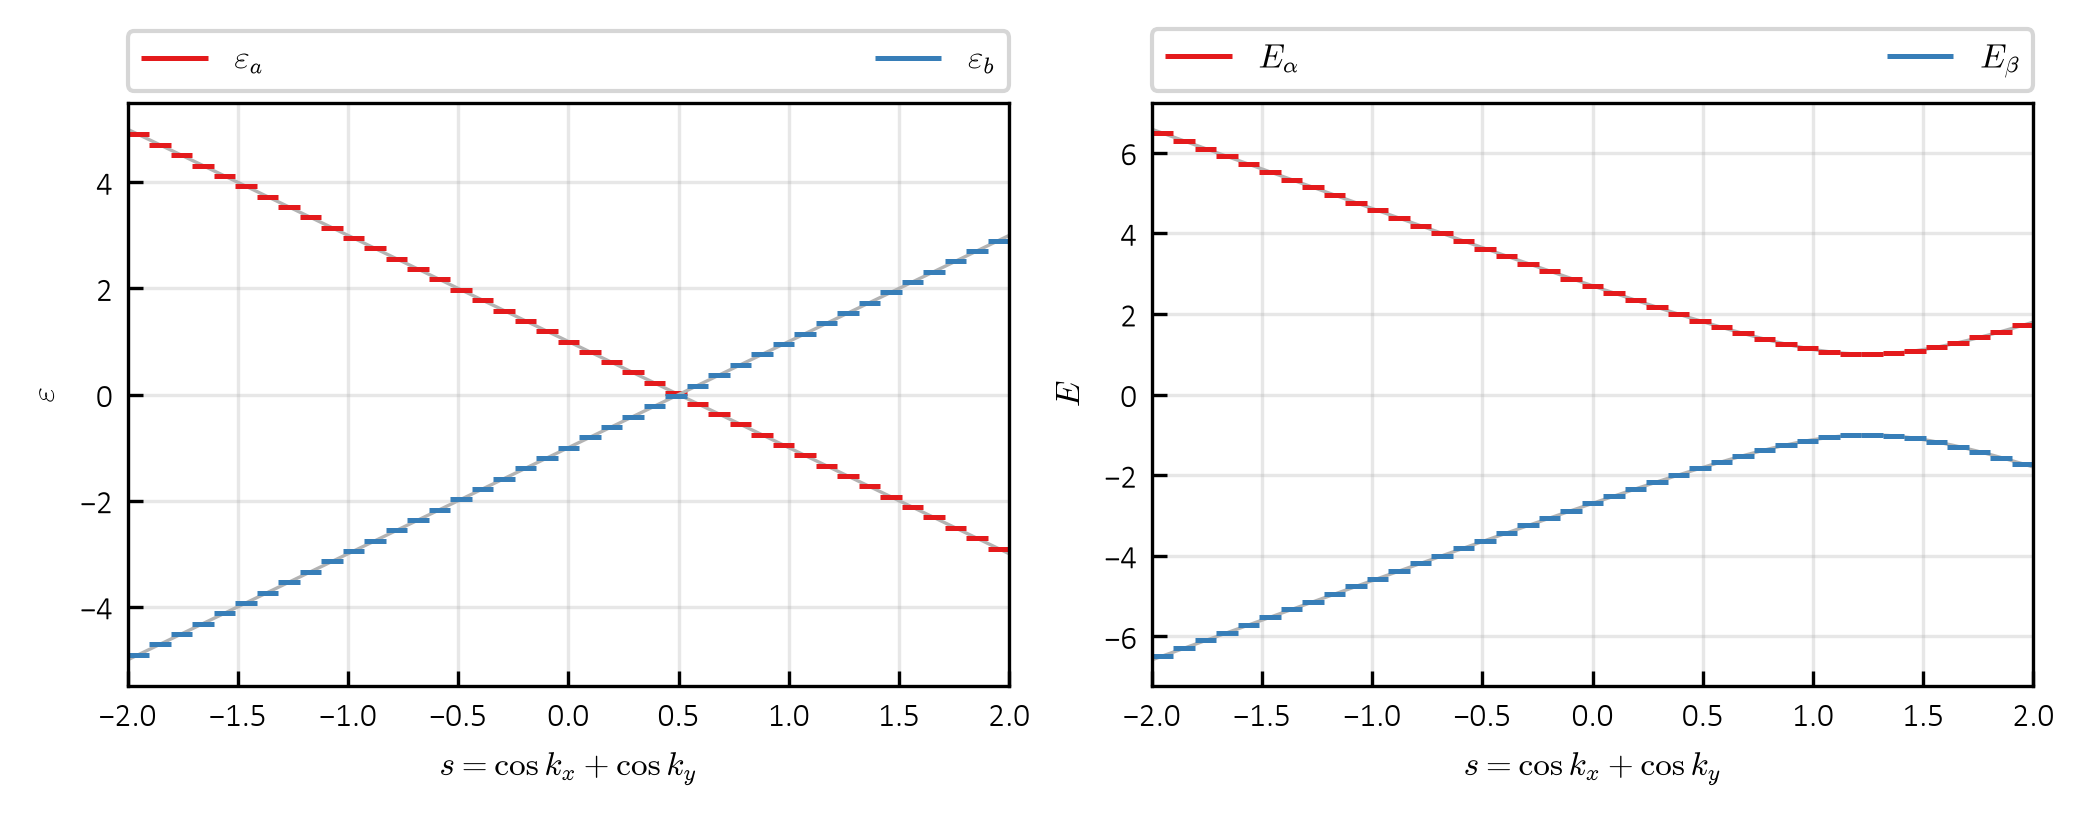

In [15]:
o = np.argsort(sk)[::max(1, sk.size // 4000)]    # thinned, sorted in s
lb = ((r"$\varepsilon_a$", r"$\varepsilon_b$"), (r"$E_\alpha$", r"$E_\beta$"))

with pt.figure(shape=(1, 2), h=0.8, w=2.0, sharex=True) as fg:
    for a, j0, lab in zip(fg.ax, (0, 4), lb):
        for j in range(2):
            a.plot(sk[o], ek[j0 + j][o], color="0.7", lw=0.8)
            a.hlines(eb_[j0 + j], se[:-1], se[1:], color=SET1_LIST[j], lw=1.2,
                     label=lab[j])
        format_ax(a, x=se, xlabel=r"$s=\cos k_x+\cos k_y$")
        add_legend(a, top=True, ncol=2)
    fg.ax[0].set_ylabel(r"$\varepsilon$")
    fg.ax[1].set_ylabel(r"$E$")

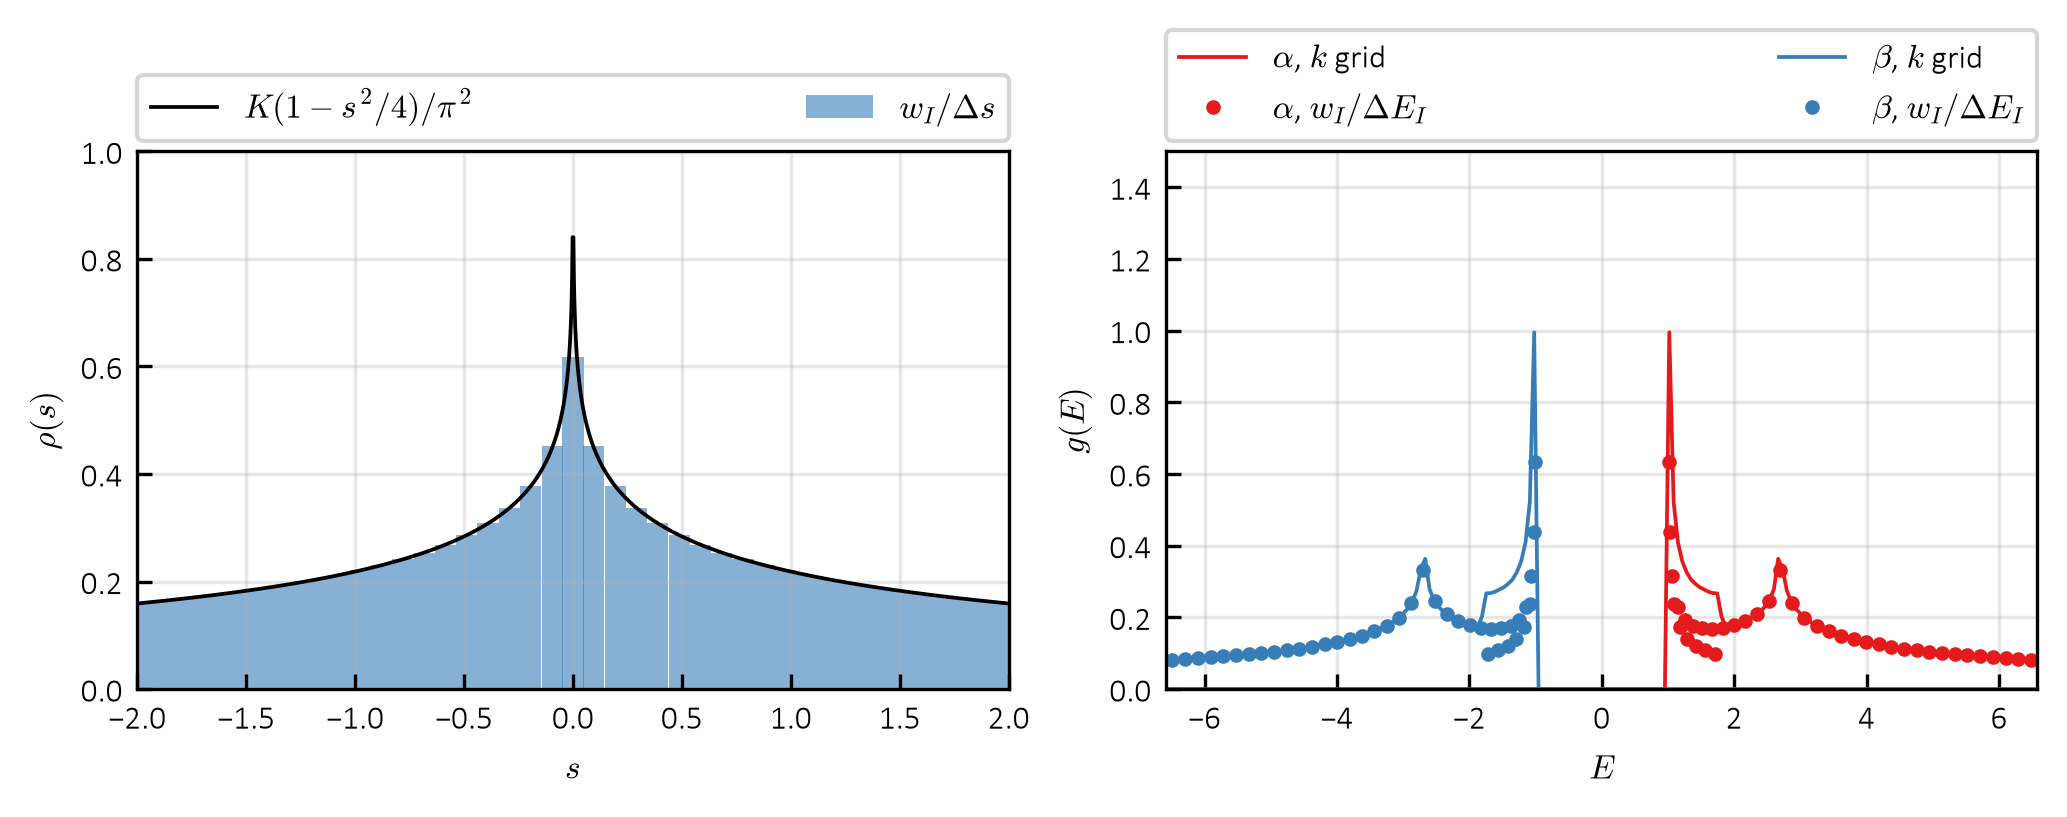

In [16]:
ds = se[1] - se[0]
sx = np.linspace(-2.0, 2.0, 2001)[1:-1]
sx = sx[np.abs(sx) > 1e-6]
rho = ellipk(1.0 - 0.25 * sx**2) / np.pi**2      # exact density of s

# energy width of every bin and histogram of the fine grid energies
lo, hi = np.full((2, ns), np.inf), np.full((2, ns), -np.inf)
for j in range(2):
    np.minimum.at(lo[j], ib, ek[4 + j])
    np.maximum.at(hi[j], ib, ek[4 + j])
ee = np.linspace(ek[4:].min(), ek[4:].max(), 201)
ec, de = 0.5 * (ee[:-1] + ee[1:]), ee[1] - ee[0]

with pt.figure(shape=(1, 2), h=0.8, w=2.0) as fg:
    a = fg.ax[0]
    a.bar(sb, w / ds, width=ds, color=SET1_LIST[1], alpha=0.6, label=r"$w_I/\Delta s$")
    a.plot(sx, rho, color="k", lw=0.9, label=r"$K(1-s^2/4)/\pi^2$")
    format_ax(a, x=se, xlabel=r"$s$", ylabel=r"$\rho(s)$", ylim=(0.0, 1.0))
    add_legend(a, top=True, ncol=2)

    a = fg.ax[1]
    for j, lab in enumerate((r"$\alpha$", r"$\beta$")):
        gk = np.histogram(ek[4 + j], bins=ee)[0] / (sk.size * de)
        a.plot(ec, gk, color=SET1_LIST[j], lw=0.9, label=rf"{lab}, $k$ grid")
        a.plot(eb_[4 + j], w / (hi[j] - lo[j]), color=SET1_LIST[j], lw=0.0, marker="o",
               ms=2.5, label=rf"{lab}, $w_I/\Delta E_I$")
    format_ax(a, x=ee, xlabel=r"$E$", ylabel=r"$g(E)$", ylim=(0.0, 1.5))
    add_legend(a, top=True, ncol=2)

In [22]:
import colormaps as cmaps
from matplotlib.colors import LogNorm
from utils.plotting_utils import color_map

nu = 41                                       # bins in tau, odd keeps u = 0 inside a bin
te = np.linspace(-1.0, 1.0, nu + 1)          # bin edges in tau = u / (2 - |s|)


def tau(s, u):
    """Reduced coordinate u / (2 - |s|) in [-1, 1], zero where |s| = 2."""
    r = 2.0 - np.abs(s)
    return np.where(r > 1e-12, u / np.where(r > 1e-12, r, 1.0), 0.0)


tk = tau(sk, uk)
it = np.clip(((tk + 1.0) * 0.5 * nu).astype(int), 0, nu - 1)
ic = ib * nu + it                            # flat cell index, s bin times nu plus tau bin
cn2 = np.bincount(ic, minlength=ns * nu)
w2 = (cn2 / sk.size).reshape(ns, nu)         # cell weights, sum to 1
print("sum over tau equals w:", np.abs(w2.sum(axis=1) - w).max(),
      "| empty cells:", int((cn2 == 0).sum()), "| points per cell:", cn2.min(), "to", cn2.max())
print("tau -> -tau asymmetry of the weights:", np.abs(w2 - w2[:, ::-1]).max())

sum over tau equals w: 6.938893903907228e-18 | empty cells: 0 | points per cell: 232 to 12881
tau -> -tau asymmetry of the weights: 0.0


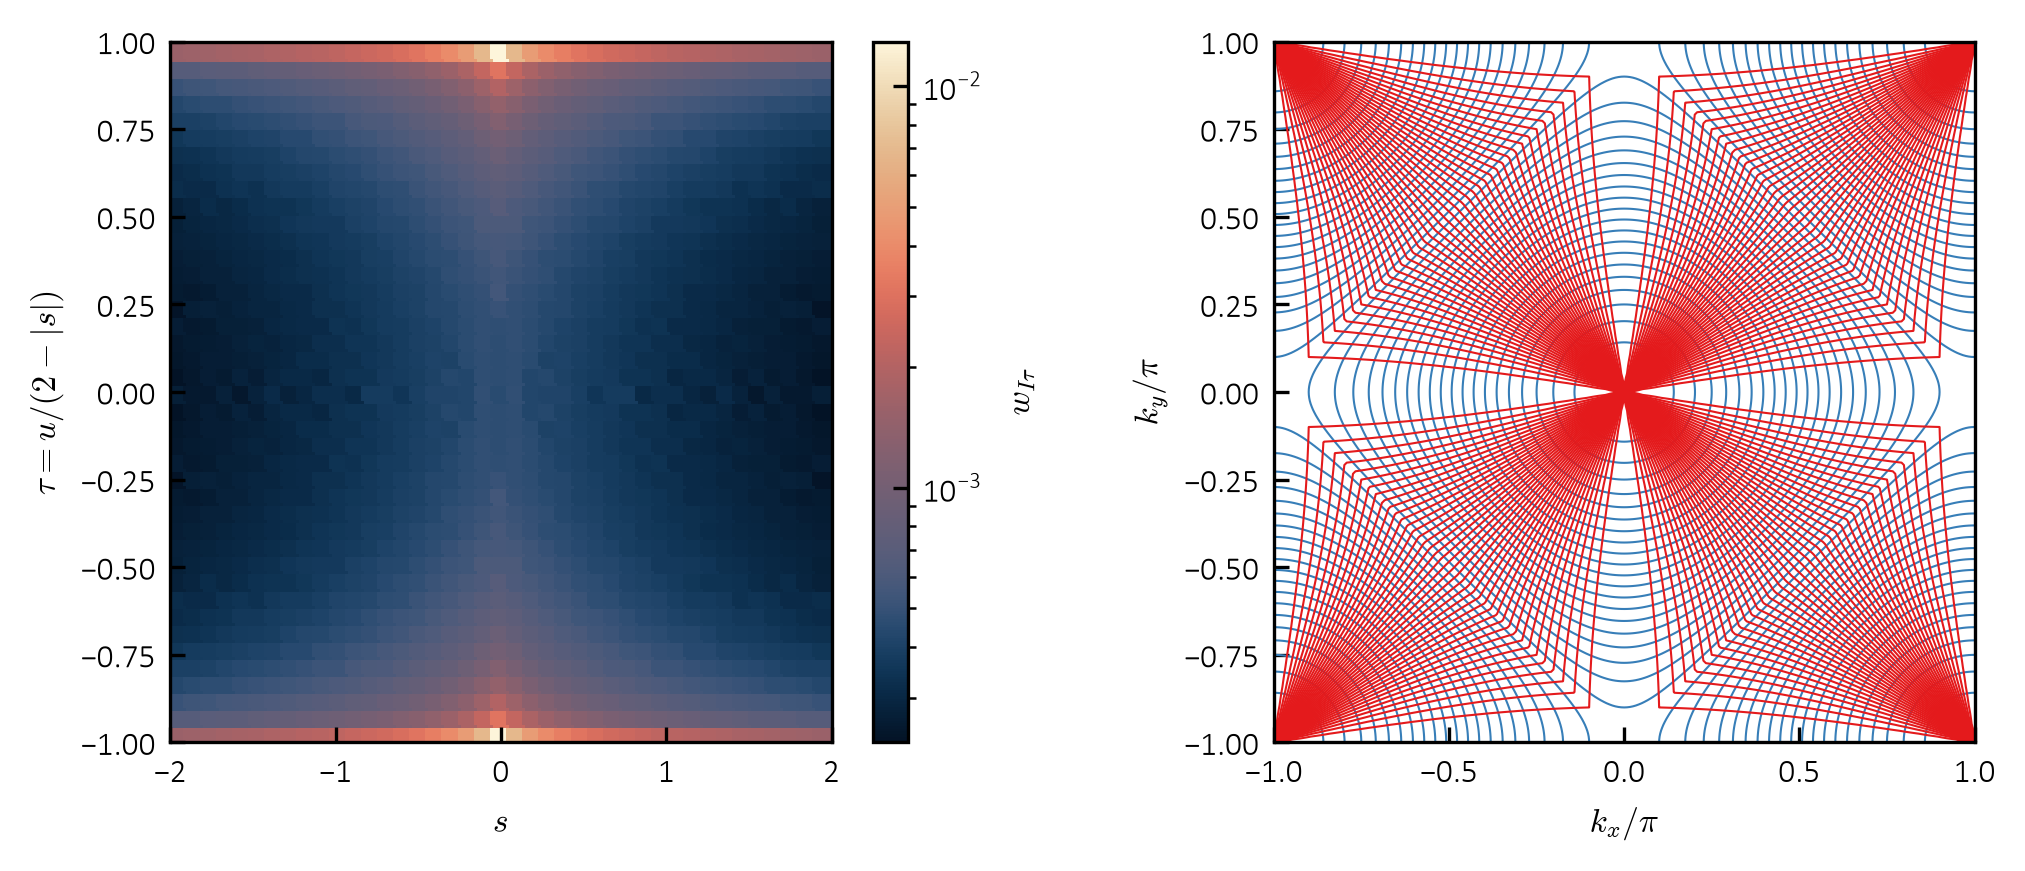

In [23]:
kq = np.linspace(-np.pi, np.pi, 241)
cx, cy = np.meshgrid(np.cos(kq), np.cos(kq), indexing="ij")

with pt.figure(shape=(1, 2), h=0.85, w=2.0) as fg:
    a = fg.ax[0]
    im = color_map(a, se, te, w2.T, norm=LogNorm(vmin=w2.min(), vmax=w2.max()))
    fg.colorbar(im, r"$w_{I\tau}$", ax=a)
    format_ax(a, x=se, xlabel=r"$s$", ylabel=r"$\tau=u/(2-|s|)$", grid=False)

    a = fg.ax[1]                             # the same cells in the Brillouin zone
    a.contour(kq / np.pi, kq / np.pi, (cx + cy).T, levels=se[1:-1], colors=[SET1_LIST[1]],
              linewidths=0.5, linestyles="solid")
    a.contour(kq / np.pi, kq / np.pi, tau(cx + cy, cx - cy).T, levels=te[1:-1],
              colors=[SET1_LIST[0]], linewidths=0.5, linestyles="solid")
    format_ax(a, x=kq / np.pi, xlabel=r"$k_x/\pi$", ylabel=r"$k_y/\pi$", grid=False)
    a.set_aspect("equal")

In [29]:
from scipy.optimize import brentq
from scipy.special import expit

# sub bins: s values and weights inside every bin, for averages of functions of s
nsub = 16
jb = ib * nsub + np.clip(((sk - se[ib]) / ds * nsub).astype(int), 0, nsub - 1)
cj = np.bincount(jb, minlength=ns * nsub)
ws = (cj / np.repeat(cnt, nsub)).reshape(ns, nsub)
ss = (np.bincount(jb, weights=sk, minlength=ns * nsub) / np.maximum(cj, 1)).reshape(ns, nsub)


def coh(s, d, m):
    """Coherence factors u^2 - v^2 and u v on shell values s."""
    xi = 0.5 * bq["gap"] - (bq["ta"] - bq["tb"]) * s - 0.5 * p.h * m
    ek = np.hypot(xi, d)
    return np.stack((xi / ek, 0.5 * d / ek))


def binned(d, m):
    """Binned quasiparticle energies (2, ns) and coherence factors (2, ns)."""
    return np.sum(ws * mf(ss, d, m)[4:], axis=-1), np.sum(ws * coh(ss, d, m), axis=-1)


def mf_sums(n, c, wc):
    """Gap, imbalance and filling sums; n (2, ...), c (2, ...), weights wc."""
    dn = n[1] - n[0]
    return p.v * np.sum(wc * c[1] * dn), -np.sum(wc * c[0] * dn), np.sum(wc * (n[0] + n[1]))


def eq_bins(t, d, m, mix=0.5, tol=1e-12, nmax=2000):
    """Thermal equilibrium on the s bins: d, m, chemical potential, occupations."""
    for i in range(nmax):
        e, c = binned(d, m)
        mc = brentq(lambda z: np.sum(w * expit(-(e - z) / t)) - p.n,
                    e.min() - 1.0, e.max() + 1.0, xtol=1e-14)
        n = expit(-(e - mc) / t)
        dt, mt, _ = mf_sums(n, c, w)
        if max(abs(dt - d), abs(mt - m)) < tol:
            break
        d, m = d + mix * (dt - d), m + mix * (mt - m)
    return d, m, mc, n, i


print("sub bins vs fine grid average:", np.abs(binned(d, m)[0] - eb_[4:]).max())

tq, nr = 0.3, 40                            # test temperature, cartesian reference grid
sc = eu.solve_eq(eu.tb_2d(nr, **bq), p, t=tq, d=d, m=m, **cfg["equilibrium"]["solve"])
dq, mq, mc, nq, iq = eq_bins(tq, d, m)
print(f"cartesian nk = {nr}: d = {sc.d:.6f}, m = {sc.m:.6f}")
print(f"bins ns = {ns}:       d = {dq:.6f}, m = {mq:.6f}  ({iq} iterations)")

# the same sums on the (s, tau) cells: occupations and factors repeated along tau
eq, cq = binned(dq, mq)
nc = np.repeat(nq[:, :, None], nu, axis=2)
print("cell sums - bin sums:", np.subtract(mf_sums(nc, cq[:, :, None], w2), mf_sums(nq, cq, w)))

sub bins vs fine grid average: 5.948607401329298e-06
cartesian nk = 40: d = 0.935193, m = -0.691778
bins ns = 41:       d = 0.935586, m = -0.691736  (174 iterations)
cell sums - bin sums: [ 0.00000000e+00 -1.11022302e-16  0.00000000e+00]


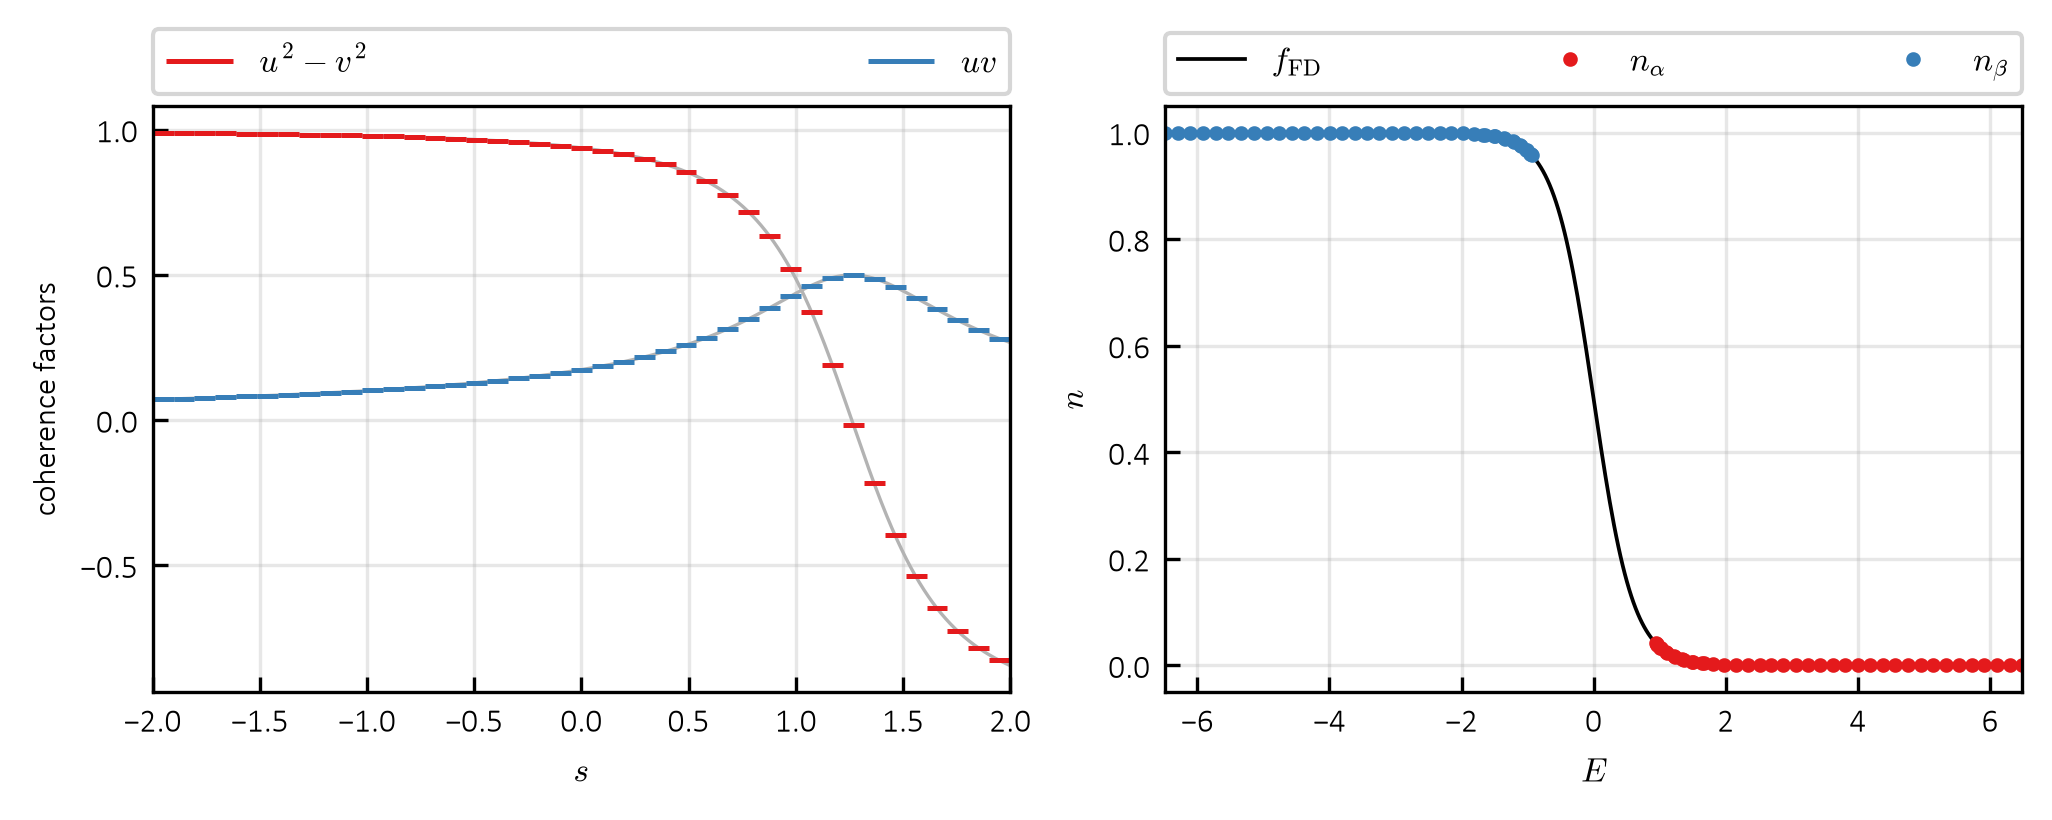

In [30]:
ck = coh(sk, dq, mq)
lc = (r"$u^2-v^2$", r"$uv$")

with pt.figure(shape=(1, 2), h=0.8, w=2.0) as fg:
    a = fg.ax[0]
    for j in range(2):
        a.plot(sk[o], ck[j][o], color="0.7", lw=0.8)
        a.hlines(cq[j], se[:-1], se[1:], color=SET1_LIST[j], lw=1.2, label=lc[j])
    format_ax(a, x=se, xlabel=r"$s$", ylabel="coherence factors")
    add_legend(a, top=True, ncol=2)

    a = fg.ax[1]
    xe = np.linspace(eq.min(), eq.max(), 400)
    a.plot(xe, expit(-(xe - mc) / tq), color="k", lw=0.9, label=r"$f_{\mathrm{FD}}$")
    for j, lab in enumerate((r"$n_\alpha$", r"$n_\beta$")):
        a.plot(eq[j], nq[j], color=SET1_LIST[j], lw=0.0, marker="o", ms=2.5, label=lab)
    format_ax(a, x=xe, xlabel=r"$E$", ylabel=r"$n$")
    add_legend(a, top=True, ncol=3)

In [31]:
import jax
import jax.numpy as jnp
import EI.ei_phonon as pb

bt = cfg["open_system"]["bath"]["pars"]      # amp, dip, cs, w0, gam, qd, ...
S1 = np.diag([2.0 * bq["ta"], 2.0 * bq["tb"], 0.0, 0.0])    # velocity: C1 = z^T S1 z'
S2 = np.zeros((4, 4))                                        # dipole:   C2 = dip z^T S2 z'
S2[2, 1] = S2[3, 0] = 1.0
S2[0, 3] = S2[1, 2] = -1.0


def geom(kd, ks):
    """Geometry factors of pairs (destination kd, source ks), (Nd, Ns), with 1 / w_q.

    g1 = (X_TE^2 + r2 X_TM^2) / w_q, g2 = (sin^2 phi + r2 cos^2 phi) / w_q,
    q = kd - ks in the first zone, velocities at the midpoint ks + q / 2.
    """
    qx = np.mod(kd[:, None, 0] - ks[None, :, 0] + np.pi, 2.0 * np.pi) - np.pi
    qy = np.mod(kd[:, None, 1] - ks[None, :, 1] + np.pi, 2.0 * np.pi) - np.pi
    qm = np.hypot(qx, qy)
    ph = np.arctan2(qy, qx)
    cp, sn = np.cos(ph), np.sin(ph)
    hx, hy = np.sin(ks[None, :, 0] + 0.5 * qx), np.sin(ks[None, :, 1] + 0.5 * qy)
    om = np.maximum(np.hypot(bt["w0"], bt["cs"] * qm), 1e-30)
    r2 = (bt["w0"] / om) ** 2
    ok = (qm <= bt["qd"]) / om
    return (ok * ((-sn * hx + cp * hy) ** 2 + r2 * (cp * hx + sn * hy) ** 2),
            ok * (sn * sn + r2 * cp * cp))


def orb(s, d, m):
    """Orbital vectors z = (a, b, ea a, eb b) of alpha and beta, shape (2, 4, ...)."""
    ea, eb = mf(s, d, m)[:2]
    x = coh(s, d, m)[0]
    u, v = np.sqrt(0.5 * (1.0 + x)), np.copysign(np.sqrt(0.5 * (1.0 - x)), d)
    return np.stack([np.stack((qa, qb, ea * qa, eb * qb)) for qa, qb in ((u, -v), (v, u))])


def vertex(kd, ks, d, m):
    """sum over polarisations of |M|^2 for cartesian pairs, (nu, mu, Nd, Ns)."""
    g1, g2 = geom(kd, ks)
    zd, zs = orb(su(kd)[0], d, m), orb(su(ks)[0], d, m)
    c1 = np.einsum("ab,xan,ybm->xynm", S1, zd, zs)
    c2 = bt["dip"] * np.einsum("ab,xan,ybm->xynm", S2, zd, zs)
    return bt["amp"] * (g1 * c1**2 + g2 * c2**2)


# check against pb.g_mat on random pairs of the reference grid
rng = np.random.default_rng(0)
ik, ip = rng.integers(0, bd.size, (2, 200))
qv = np.mod(bd.k[ik] - bd.k[ip] + np.pi, 2.0 * np.pi) - np.pi
stc = ej.mf_state(bd, p, d, m)
bc = pb.PhononBath(t=1.0, k=bd.k, **bt)
gm = jax.vmap(lambda a, b, q: pb.g_mat(stc, bc, a, b, q))(jnp.asarray(ik), jnp.asarray(ip),
                                                         jnp.asarray(qv))
ref = (np.abs(np.asarray(gm)) ** 2).sum(axis=1)             # (pairs, nu, mu)
mine = np.stack([vertex(bd.k[[a]], bd.k[[b]], d, m)[:, :, 0, 0] for a, b in zip(ik, ip)])
print("vertex vs pb.g_mat:", np.abs(mine - ref).max() / np.abs(ref).max())

vertex vs pb.g_mat: 7.632630776905789e-16


In [44]:
def cell(k):
    """Flat cell index (s bin times nu plus tau bin) of momenta k (N, 2)."""
    s, u = su(k)
    i = np.clip(np.searchsorted(se, s, side="right") - 1, 0, ns - 1)
    return i * nu + np.clip(((tau(s, u) + 1.0) * 0.5 * nu).astype(int), 0, nu - 1)


nv = 160                                     # cartesian grid for the pair averages
bv = eu.tb_2d(nv, **bq)
iv = cell(bv.k)
cv = np.bincount(iv, minlength=ns * nu)
print("grid points per cell:", cv.min(), "to", cv.max())


def cavg(f):
    """Average over the destination cells of values f (..., N) on the nv grid."""
    f = np.asarray(f)
    g = f.reshape(-1, f.shape[-1])
    z = np.stack([np.bincount(iv, weights=y, minlength=ns * nu) for y in g]) / cv
    return z.reshape(f.shape[:-1] + (ns * nu,))


mu_ = 0                                      # source band, 0 alpha, 1 beta
i0 = int(np.argmin(eb_[4 + mu_]))            # source s bin: gap edge
a0 = nu - 1                                  # source tau bin
src = np.flatnonzero(iv == i0 * nu + a0)     # source points
# cartesian: average over the source points, destination k resolved
mk = vertex(bv.k, bv.k[src], d, m)[:, mu_].mean(axis=-1)    # (nu, N)

# cells: averaged geometry times bin averaged coherence
g1, g2 = (cavg(g.mean(axis=-1)) for g in geom(bv.k, bv.k[src]))    # (cells,)
zz = orb(ss, d, m)                                                 # (2, 4, ns, nsub)
mo = np.einsum("is,xais,xcis->xiac", ws, zz, zz)                   # moments (2, ns, 4, 4)
c1 = np.einsum("ab,xiac,cd,bd->xi", S1, mo, S1, mo[mu_, i0])       # <C1^2> (nu, ns)
c2 = bt["dip"] ** 2 * np.einsum("ab,xiac,cd,bd->xi", S2, mo, S2, mo[mu_, i0])
mz = bt["amp"] * (g1 * np.repeat(c1, nu, axis=1) + g2 * np.repeat(c2, nu, axis=1))

er = np.abs(cavg(mk) - mz).max() / mz.max()
print("cells against the cell average of the cartesian vertex:", er)

grid points per cell: 0 to 321
cells against the cell average of the cartesian vertex: nan


/tmp/ipykernel_95910/2706176681.py:19: RuntimeWarning: invalid value encountered in divide
  z = np.stack([np.bincount(iv, weights=y, minlength=ns * nu) for y in g]) / cv


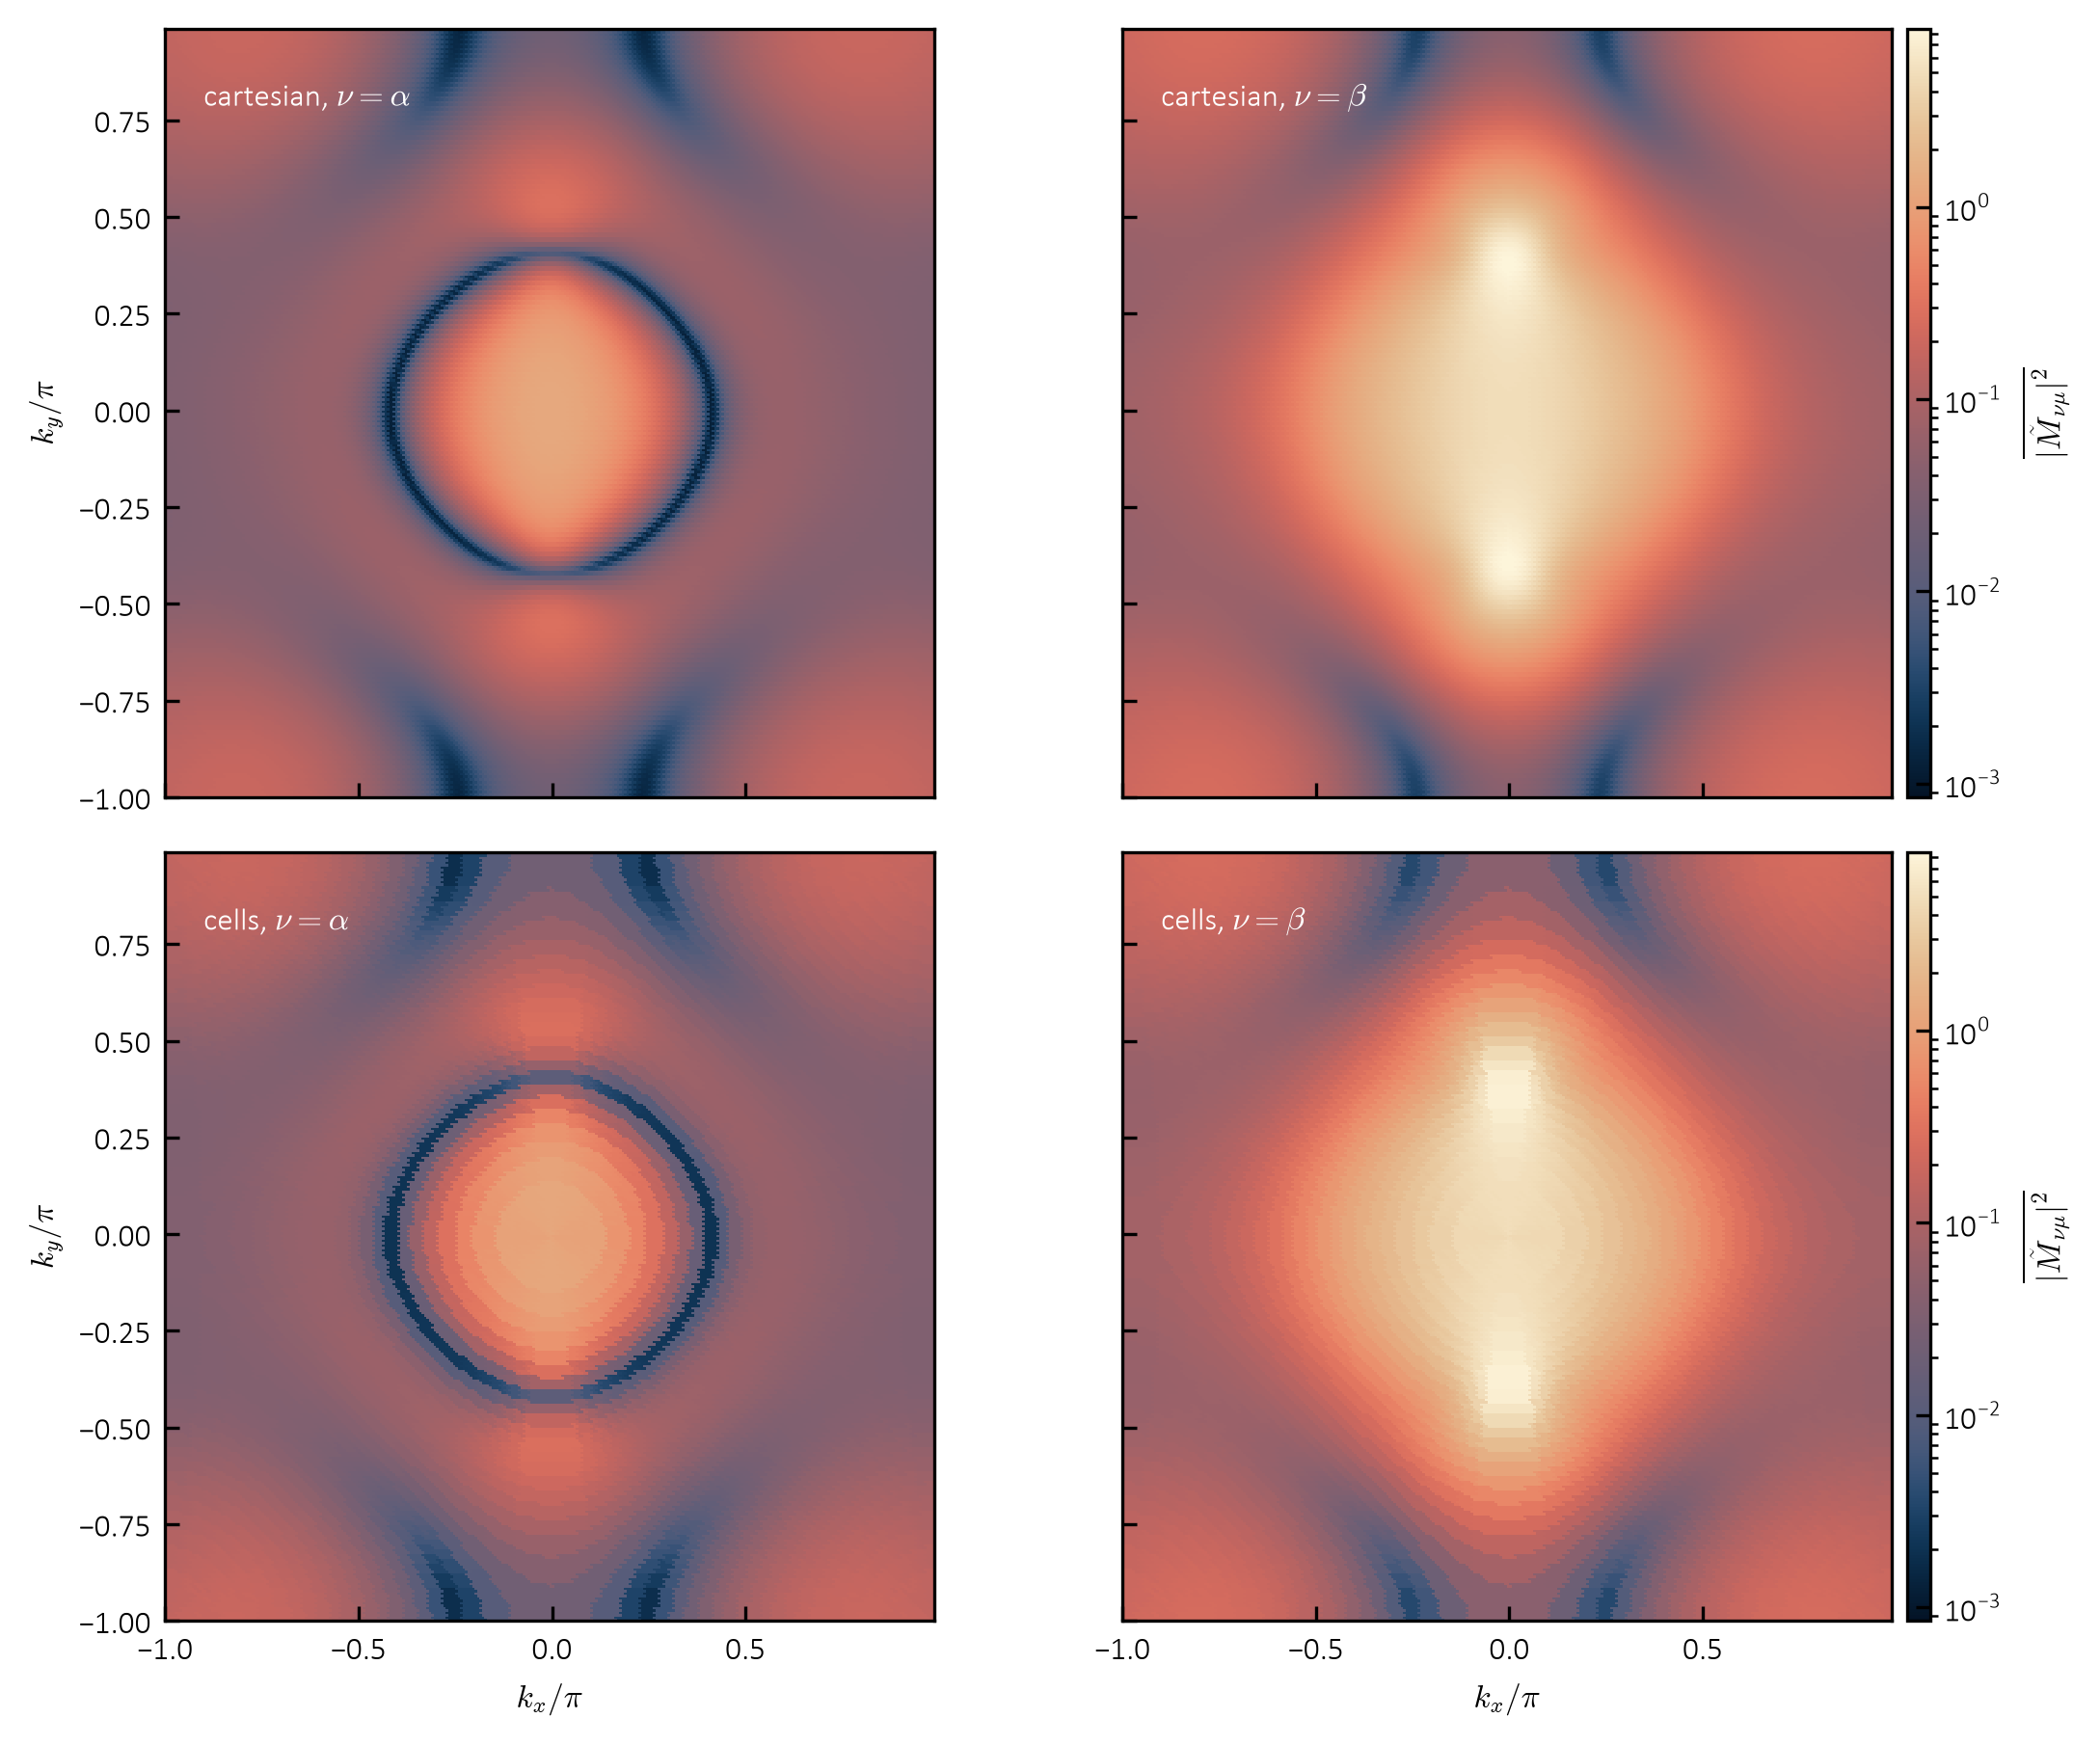

In [45]:
kv = np.unique(bv.k[:, 0]) / np.pi
bl = (r"\alpha", r"\beta")
vm = max(mk.max(), mz.max())
nm = LogNorm(vmin=1e-4 * vm, vmax=vm)

with pt.figure(shape=(2, 2), h=1.7, w=2.0, sharex=True, sharey=True) as fg:
    for r, (z, lab) in enumerate(((mk, "cartesian"), (mz[:, iv], "cells"))):
        for j, a in enumerate(fg.ax[r]):
            im = color_map(a, kv, kv, z[j].reshape(nv, nv).T, norm=nm)
            a.text(0.05, 0.93, rf"{lab}, $\nu={bl[j]}$", transform=a.transAxes,
                   ha="left", va="top", color="white")
            format_ax(a, x=kv, grid=False)
            a.set_aspect("equal")
        fg.colorbar(im, r"$\overline{|\tilde M_{\nu\mu}|^2}$", ax=fg.ax[r, -1], external=True)
    for a in fg.ax[1]:
        a.set_xlabel(r"$k_x/\pi$")
    for a in fg.ax[:, 0]:
        a.set_ylabel(r"$k_y/\pi$")